# Inkling-2-Mini on 1x CMP 170HX (SM80, 140 W) — vLLM with an SM80 patch and DSpark, vs llama.cpp

| Metric (1 card, 140 W) | Value |
|---|---|
| Decode, c=1, temperature 0 | **167 tok/s** code · **189 tok/s** structured JSON · **94 tok/s** prose (vLLM + DSpark k=7) |
| Best aggregate | **511 tok/s** at c=16 (vLLM + DSpark k=7) |
| Prefill | **4,700 tok/s** at 23,806 prompt tokens |
| TTFT | 0.08 s short prompt · 5.07 s at 23,806 tokens |

![chart](../assets/charts/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp.png)

```
docker pull vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e
```

Evidence: [results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/](../results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/README.md)

In [1]:
# --- Status cell -------------------------------------------------------
# LIVE = False replays the committed receipts under results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/.
# LIVE = True is not wired: the live harness is results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/harness/ (see Reproduce).
import sys
from pathlib import Path
LIVE = False
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RESULTS_DIR = REPO / "results" / "2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp"
sys.path.insert(0, str(RESULTS_DIR))
import summarize as S
from IPython.display import display, Markdown, Image
def render_table(headers, rows):
    out = "| " + " | ".join(headers) + " |\n|" + "---|" * len(headers) + "\n"
    out += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(out))
T = S.table()
print("LIVE =", LIVE, "| receipts:", RESULTS_DIR.relative_to(REPO), "| result rows:", len(T))

LIVE = False | receipts: results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp | result rows: 62


## 1. TL;DR

**Verdict (measured): Inkling-2-Mini runs on one CMP 170HX, and vLLM with DSpark is the fast path: 2.2x to 4.4x llama.cpp at one user.** The vLLM image for this model is built for Blackwell and Hopper only. Six small Python patches (no rebuild) make it run on SM80. GSM8K (first 100 test questions): 99/100 on the patched vLLM, 98/100 on llama.cpp.

- **Use DSpark with probabilistic draft sampling at temperature > 0.** On the same card at temperature 1 it beats greedy draft sampling by 6–17% (section 2, same-card check). At temperature 0 the two are about equal: the gap in the main table (166.9 vs 154.5 code) is the card, not the draft method (see the caution in section 2). DSpark is fixed at k=7 by the checkpoint; k=3 and k=5 refuse to start.
- **Speculation is the lever, not memory clock.** Without DSpark, vLLM decodes at 78.8–79.7 tok/s on a 1,600 GB/s card and 76.3 tok/s on a 1,313 GB/s card (−4% for −18% bandwidth). The 48 layer visits per token (12 core layers × 3 passes) make one-user decode latency-bound.
- **llama.cpp b12600 works with no patch** (official ggml-org IQ4_NL GGUF), but decodes at 42.7 tok/s and prefills at 315–627 tok/s, 4.9x (5.9k tokens) to 11.4x (23.8k tokens) slower than vLLM. Use it only where vLLM is not an option.
- Prose gains the least from DSpark (94 vs 79 tok/s): acceptance depends on the text.

In [2]:
pins = [
 ("Hardware", "1x CMP 170HX (GA100, SM80), 64 GiB unlocked, 74 SMs, PCIe Gen2 x16, host driver (no VM); HBM per card in section 2"),
 ("Power / cooling", "nvidia-smi -pl 140 (all cards); forced chassis airflow, GPU-temperature fan loop; fail-closed guard 80 °C core / 85 °C memory / any Xid"),
 ("Driver stack", "NVIDIA open kernel modules 615.71.09, kernel 7.0.2-6-pve; amoghmunikote/cmpunlocker @ 88e39ce67488796b2c6c716fe8f9b4e6e943a55e + club patch set (docs/CMP170HX-UNDERSTANDING.md §8)"),
 ("vLLM image", "vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e (tag inkling-2-mini, vLLM 0.1.dev25855+g7cb5dae22, torch 2.14.0+cu130, Python 3.14; TORCH_CUDA_ARCH_LIST=10.0+PTX 10.3+PTX)"),
 ("SM80 patch", "results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/patches/make-sm80-patch.sh → vllm/models/inkling2 mounted read-only over the image's copy; full diff patches/inkling2-sm80.diff"),
 ("vLLM model", "thinkingmachines/Inkling-2-Mini @ ed40e7da625f594fc9c4990f5f66be24873c22d7 (NVFP4 experts + MXFP8, bundled DSpark draft head; Apache-2.0)"),
 ("vLLM serve", "--max-model-len 32768 --reasoning-parser inkling --limit-mm-per-prompt {\"image\":0} [--compilation-config {\"custom_ops\":[\"none\"]} --speculative-config {\"method\":\"dspark\",\"num_speculative_tokens\":7,\"draft_sample_method\":\"probabilistic\"}]"),
 ("llama.cpp", "ggml-org/llama.cpp b12600 = 29b52d398b294509746ec0a3f28948a3107c0213, CMAKE_CUDA_ARCHITECTURES=80, built in nvidia/cuda@sha256:520292dbb4f755fd360766059e62956e9379485d9e073bbd2f6e3c20c270ed66 (12.8.1-devel-ubuntu24.04)"),
 ("llama.cpp model", "ggml-org/Inkling-2-Mini-GGUF @ db61c5b492a6a034d986328d28274af0a439aa6c, Inkling-2-Mini-IQ4_NL.gguf (17.6 GB)"),
 ("llama.cpp serve", "llama-server -ngl 999 -fa on --jinja -c 65536 -np 4 (decode, concurrency) / -np 1 -ub 2048 -b 2048 (prefill)"),
 ("Accuracy set", "openai/gsm8k main test @ e53f048856ff4f594e959d75785d2c2d37b678ee, first 100 questions, temperature 0, reasoning_effort low (MIT)"),
]
render_table(["Pin", "Value"], pins)

| Pin | Value |
|---|---|
| Hardware | 1x CMP 170HX (GA100, SM80), 64 GiB unlocked, 74 SMs, PCIe Gen2 x16, host driver (no VM); HBM per card in section 2 |
| Power / cooling | nvidia-smi -pl 140 (all cards); forced chassis airflow, GPU-temperature fan loop; fail-closed guard 80 °C core / 85 °C memory / any Xid |
| Driver stack | NVIDIA open kernel modules 615.71.09, kernel 7.0.2-6-pve; amoghmunikote/cmpunlocker @ 88e39ce67488796b2c6c716fe8f9b4e6e943a55e + club patch set (docs/CMP170HX-UNDERSTANDING.md §8) |
| vLLM image | vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e (tag inkling-2-mini, vLLM 0.1.dev25855+g7cb5dae22, torch 2.14.0+cu130, Python 3.14; TORCH_CUDA_ARCH_LIST=10.0+PTX 10.3+PTX) |
| SM80 patch | results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/patches/make-sm80-patch.sh → vllm/models/inkling2 mounted read-only over the image's copy; full diff patches/inkling2-sm80.diff |
| vLLM model | thinkingmachines/Inkling-2-Mini @ ed40e7da625f594fc9c4990f5f66be24873c22d7 (NVFP4 experts + MXFP8, bundled DSpark draft head; Apache-2.0) |
| vLLM serve | --max-model-len 32768 --reasoning-parser inkling --limit-mm-per-prompt {"image":0} [--compilation-config {"custom_ops":["none"]} --speculative-config {"method":"dspark","num_speculative_tokens":7,"draft_sample_method":"probabilistic"}] |
| llama.cpp | ggml-org/llama.cpp b12600 = 29b52d398b294509746ec0a3f28948a3107c0213, CMAKE_CUDA_ARCHITECTURES=80, built in nvidia/cuda@sha256:520292dbb4f755fd360766059e62956e9379485d9e073bbd2f6e3c20c270ed66 (12.8.1-devel-ubuntu24.04) |
| llama.cpp model | ggml-org/Inkling-2-Mini-GGUF @ db61c5b492a6a034d986328d28274af0a439aa6c, Inkling-2-Mini-IQ4_NL.gguf (17.6 GB) |
| llama.cpp serve | llama-server -ngl 999 -fa on --jinja -c 65536 -np 4 (decode, concurrency) / -np 1 -ub 2048 -b 2048 (prefill) |
| Accuracy set | openai/gsm8k main test @ e53f048856ff4f594e959d75785d2c2d37b678ee, first 100 questions, temperature 0, reasoning_effort low (MIT) |

## 2. Visible results

All numbers are **measured** on 2026-11-21, one card per server, 140 W. Token counts come from the final streamed `usage` object. Decode tok/s = (completion_tokens − 1) / (total − TTFT). Every reply ran to the 768-token cap (the model reasons even at `reasoning_effort: none`). Prompts are in `harness/bench.py`.

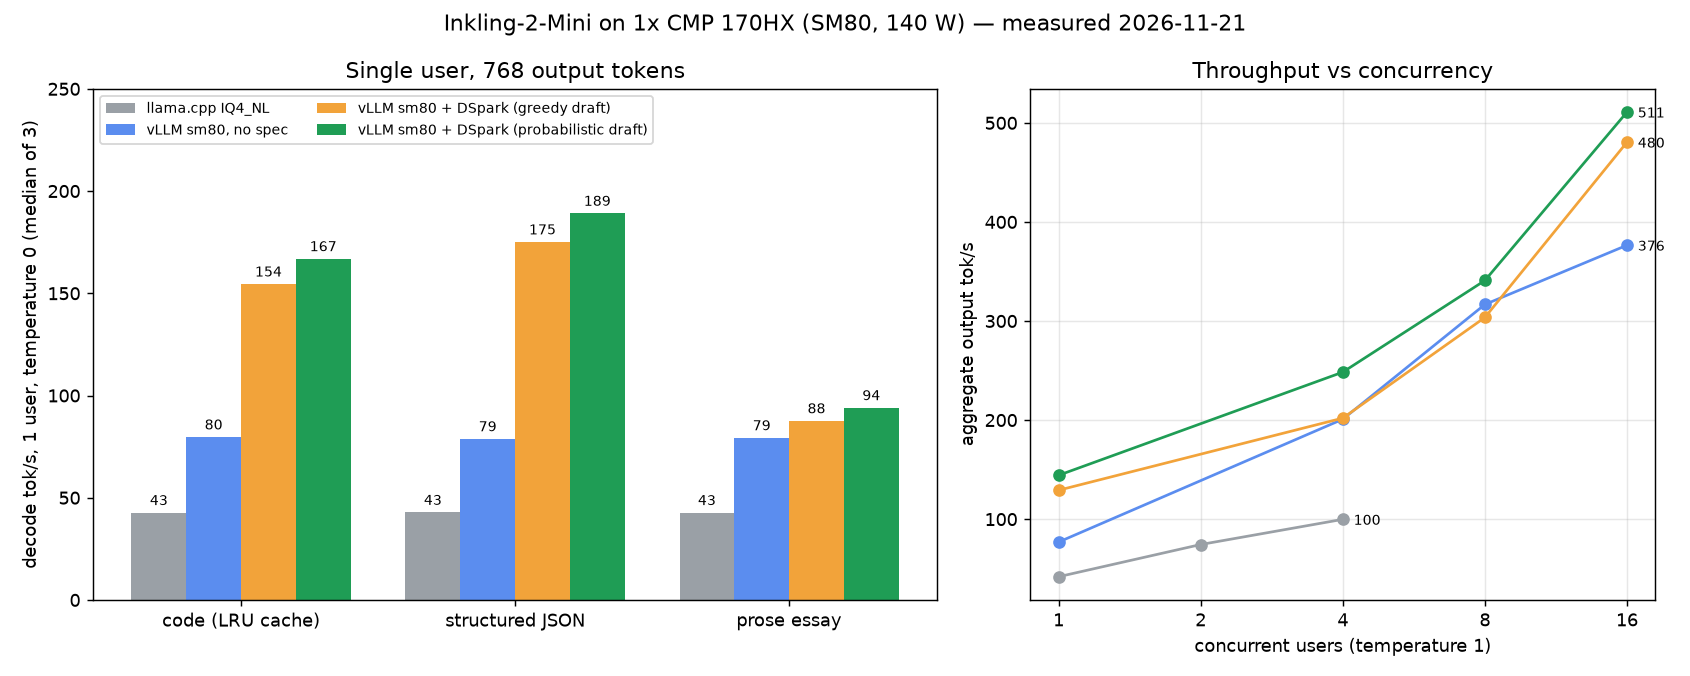

In [3]:
display(Image(filename=str(REPO / "assets/charts/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp.png")))

In [4]:
arms = [("llama-b12600-iq4nl", "llama.cpp IQ4_NL"), ("vllm-sm80p-base", "vLLM sm80, no spec (1,313 GB/s card)"),
        ("vllm-sm80p-base-gpu3", "vLLM sm80, no spec"), ("vllm-sm80p-dspark7-greedydraft", "vLLM + DSpark k=7, greedy draft"),
        ("vllm-sm80p-dspark7", "vLLM + DSpark k=7, probabilistic draft")]
rows = []
for e, name in arms:
    for temp in (0.0, 1.0):
        r = [T[(e, "c1", c, temp)] for c in ("code", "struct", "prose")]
        rows.append((name, temp, *[f"{x['median']} ({x['min']}–{x['max']})" for x in r], r[0]["ttft"]))
render_table(["Engine", "Temperature", "Code (tok/s)", "Structured (tok/s)", "Prose (tok/s)", "TTFT code (s)"], rows)

| Engine | Temperature | Code (tok/s) | Structured (tok/s) | Prose (tok/s) | TTFT code (s) |
|---|---|---|---|---|---|
| llama.cpp IQ4_NL | 0.0 | 42.7 (42.6–42.73) | 42.8 (42.76–42.78) | 42.7 (42.69–42.76) | 0.279 |
| llama.cpp IQ4_NL | 1.0 | 42.8 (42.78–42.82) | 42.6 (42.61–42.74) | 42.7 (42.66–42.75) | 0.274 |
| vLLM sm80, no spec (1,313 GB/s card) | 0.0 | 76.3 (76.09–76.3) | 76.3 (76.26–76.28) | 76.3 (76.18–76.3) | 0.076 |
| vLLM sm80, no spec (1,313 GB/s card) | 1.0 | 76.2 (76.13–76.29) | 75.7 (75.65–75.72) | 75.9 (75.83–76.02) | 0.075 |
| vLLM sm80, no spec | 0.0 | 79.7 (79.57–79.81) | 78.8 (78.56–78.98) | 79.3 (79.17–79.35) | 0.075 |
| vLLM sm80, no spec | 1.0 | 78.2 (78.08–78.37) | 77.5 (77.41–77.61) | 77.8 (77.74–77.97) | 0.076 |
| vLLM + DSpark k=7, greedy draft | 0.0 | 154.5 (154.22–154.62) | 175.1 (133.41–175.4) | 87.6 (87.23–87.84) | 0.086 |
| vLLM + DSpark k=7, greedy draft | 1.0 | 118.5 (103.56–136.81) | 129.2 (118.75–147.34) | 73.7 (72.64–74.32) | 0.089 |
| vLLM + DSpark k=7, probabilistic draft | 0.0 | 166.9 (166.87–167.01) | 189.1 (144.01–189.36) | 94.0 (93.9–94.31) | 0.081 |
| vLLM + DSpark k=7, probabilistic draft | 1.0 | 145.9 (135.18–163.6) | 188.2 (124.28–192.22) | 92.4 (92.33–93.44) | 0.082 |

Single user, median (min–max) of 3 runs per cell. Spread at temperature 1 comes from sampling: acceptance changes run to run.

**CAUTION (found after the first publish): the two DSpark rows ran on different cards.** Probabilistic ran on a card with a 170tune SM offset (+200 at 1,410 MHz); greedy ran on a card without one. Both sit on the 140 W cap during DSpark decode; telemetry shows mean SM 1,254 vs 1,196 MHz. The same-card check below separates the two effects.

In [5]:
import json, statistics as st
vm = [json.loads(l) for l in open(RESULTS_DIR / "receipts" / "vllm-dspark7-vm504-card86.jsonl")]
rows = []
for temp in (0.0, 1.0):
    pr = {c: st.median(r["decode_tok_s"] for r in vm if r["case"] == c and r["temperature"] == temp) for c in ("code", "struct", "prose")}
    gr = {c: T[("vllm-sm80p-dspark7-greedydraft", "c1", c, temp)]["median"] for c in pr}
    rows.append((temp, *[f"{pr[c]:.1f} vs {gr[c]}" for c in ("code", "struct", "prose")]))
render_table(["Temperature", "Code: probabilistic vs greedy (tok/s)", "Structured", "Prose"], rows)

| Temperature | Code: probabilistic vs greedy (tok/s) | Structured | Prose |
|---|---|---|---|
| 0.0 | 154.2 vs 154.5 | 154.2 vs 175.1 | 87.7 vs 87.6 |
| 1.0 | 135.8 vs 118.5 | 136.8 vs 129.2 | 86.5 vs 73.7 |

Same card (no SM offset) for both draft methods. Probabilistic: served later from a VM on that card (65,536 context, 2 runs at T=0, 3 at T=1, `receipts/vllm-dspark7-vm504-card86.jsonl`); greedy: the host-mode run. **Measured:** about equal at temperature 0, probabilistic +6% to +17% at temperature 1.

In [6]:
levels = ["c1", "c2", "c4", "c8", "c16"]
rows = [(name, *[T[(e, "conc", c, 1.0)]["median"] if (e, "conc", c, 1.0) in T else "—" for c in levels]) for e, name in arms]
render_table(["Engine (aggregate output tok/s, temperature 1)", "c=1", "c=2", "c=4", "c=8", "c=16"], rows)

| Engine (aggregate output tok/s, temperature 1) | c=1 | c=2 | c=4 | c=8 | c=16 |
|---|---|---|---|---|---|
| llama.cpp IQ4_NL | 41.9 | 74.4 | 99.8 | — | — |
| vLLM sm80, no spec (1,313 GB/s card) | 75.1 | — | 200.3 | 319.9 | 380.7 |
| vLLM sm80, no spec | 76.9 | — | 200.9 | 316.7 | 376.5 |
| vLLM + DSpark k=7, greedy draft | 129.2 | — | 202.0 | 303.6 | 480.5 |
| vLLM + DSpark k=7, probabilistic draft | 144.3 | — | 248.4 | 340.9 | 510.9 |

In [7]:
rows = [(name, T[k]["prompt_tokens"], T[k]["ttft"], int(T[k]["prefill"]))
        for e, name in arms + [("llama-b12600-iq4nl-ub2048-np1", "llama.cpp IQ4_NL, 1 slot, ub 2048")]
        for k in sorted(k for k in T if k[0] == e and k[1] == "prefill")]
render_table(["Engine", "Prompt tokens", "TTFT (s)", "Prefill (tok/s)"], rows)

| Engine | Prompt tokens | TTFT (s) | Prefill (tok/s) |
|---|---|---|---|
| llama.cpp IQ4_NL | 5872 | 9.367 | 627 |
| vLLM sm80, no spec (1,313 GB/s card) | 23806 | 4.979 | 4781 |
| vLLM sm80, no spec (1,313 GB/s card) | 5870 | 2.995 | 3132 |
| vLLM sm80, no spec | 23806 | 5.176 | 4599 |
| vLLM sm80, no spec | 5870 | 2.99 | 3030 |
| vLLM + DSpark k=7, probabilistic draft | 23806 | 5.066 | 4700 |
| vLLM + DSpark k=7, probabilistic draft | 5870 | 2.947 | 3070 |
| llama.cpp IQ4_NL, 1 slot, ub 2048 | 23808 | 57.593 | 413 |
| llama.cpp IQ4_NL, 1 slot, ub 2048 | 47529 | 150.724 | 315 |
| llama.cpp IQ4_NL, 1 slot, ub 2048 | 5872 | 10.739 | 547 |

Prefill prompts are salted so no prefix cache can hit. The 47.5k-token case ran on llama.cpp only: vLLM ran with `--max-model-len 32768`.

In [8]:
rows = []
for f, name in (("vllm-dspark7-metrics.txt", "probabilistic draft"), ("vllm-dspark7greedy-metrics.txt", "greedy draft")):
    m = S.spec_metrics(f)
    d, a = m["spec_decode_num_drafts_total"], m["spec_decode_num_accepted_tokens_total"]
    pos = [round(m[f"spec_decode_num_accepted_tokens_per_pos_total[{i}]"] / d, 2) for i in range(7)] if "spec_decode_num_accepted_tokens_per_pos_total[0]" in m else "—"
    rows.append((name, int(d), int(a), round(a / d, 2), round(1 + a / d, 2), pos))
render_table(["DSpark k=7", "Drafts", "Accepted tokens", "Accepted per draft", "Tokens per verify step", "Acceptance by position 1–7"], rows)

| DSpark k=7 | Drafts | Accepted tokens | Accepted per draft | Tokens per verify step | Acceptance by position 1–7 |
|---|---|---|---|---|---|
| probabilistic draft | 13611 | 22800 | 1.68 | 2.68 | [0.63, 0.38, 0.25, 0.16, 0.11, 0.09, 0.07] |
| greedy draft | 14805 | 21345 | 1.44 | 2.44 | — |

Counters from the server `/metrics` after the bench suites (all prompts, both temperatures, all concurrencies pooled).

In [9]:
g = [("vLLM + sm80 patch + DSpark k=7", *S.gsm8k("gsm8k-vllm-dspark7.jsonl")), ("llama.cpp b12600 IQ4_NL", *S.gsm8k("gsm8k-llama-iq4.jsonl"))]
render_table(["Engine", "Correct", "Questions", "Wrong (test index)"], g)
bw = S.hbm()
render_table(["Card", "Copy bandwidth (GB/s)", "HBM clock", "Used by"],
    [("gpu0", bw["gpu0"], "1,458 MHz (stock NDIV 54)", "vLLM no spec (slow-card row), llama.cpp GSM8K"),
     ("gpu1", bw["gpu1"], "1,728 MHz (NDIV 64, 170tune)", "llama.cpp speed runs, DSpark greedy draft"),
     ("gpu2", bw["gpu2"], "1,728 MHz (stock NDIV 64)", "DSpark probabilistic draft, vLLM GSM8K"),
     ("gpu3", bw["gpu3"], "1,728 MHz (NDIV 64, 170tune)", "vLLM no spec")])
render_table(["Telemetry file", "2 s samples", "Peak core (°C)", "Peak memory (°C)", "Peak power sample (W)", "Guard stops"],
    [(t["file"], t["samples"], t["core"], t["mem"], t["power"], t["stops"]) for t in S.telemetry()])

| Engine | Correct | Questions | Wrong (test index) |
|---|---|---|---|
| vLLM + sm80 patch + DSpark k=7 | 99 | 100 | [93] |
| llama.cpp b12600 IQ4_NL | 98 | 100 | [40, 93] |

| Card | Copy bandwidth (GB/s) | HBM clock | Used by |
|---|---|---|---|
| gpu0 | 1312.8 | 1,458 MHz (stock NDIV 54) | vLLM no spec (slow-card row), llama.cpp GSM8K |
| gpu1 | 1603.4 | 1,728 MHz (NDIV 64, 170tune) | llama.cpp speed runs, DSpark greedy draft |
| gpu2 | 1596.7 | 1,728 MHz (stock NDIV 64) | DSpark probabilistic draft, vLLM GSM8K |
| gpu3 | 1601.8 | 1,728 MHz (NDIV 64, 170tune) | vLLM no spec |

| Telemetry file | 2 s samples | Peak core (°C) | Peak memory (°C) | Peak power sample (W) | Guard stops |
|---|---|---|---|---|---|
| guard-llama-gsm.csv | 238 | 64.0 | 70.0 | 62.96 | 0 |
| guard-llama-iq4.csv | 647 | 72.0 | 73.0 | 154.7 | 0 |
| guard-llama-ub2048.csv | 247 | 73.0 | 74.0 | 224.83 | 0 |
| guard-vllm-base-g3.csv | 346 | 73.0 | 81.0 | 180.18 | 0 |
| guard-vllm-base.csv | 431 | 71.0 | 77.0 | 147.47 | 0 |
| guard-vllm-dspark3.csv | 16 | 48.0 | 58.0 | 56.02 | 0 |
| guard-vllm-dspark5.csv | 16 | 44.0 | 56.0 | 56.79 | 0 |
| guard-vllm-dspark7.csv | 811 | 70.0 | 75.0 | 154.52 | 0 |
| guard-vllm-dspark7greedy.csv | 346 | 69.0 | 73.0 | 153.44 | 0 |
| guard-vllm-san.csv | 133 | 48.0 | 57.0 | 156.94 | 0 |
| guard-vllm-san2.csv | 36 | 45.0 | 56.0 | 51.19 | 0 |

Power samples above 140 W are instantaneous `power.draw` readings under a 140 W cap. No guard stop and no Xid in the kernel log during the session.

## 3. Reproduce

**Hardware.** 1x CMP 170HX with 64 GiB unlocked (the vLLM server uses about 18 GiB of weights plus KV cache at `gpu-memory-utilization` 0.9), forced airflow, and the fail-closed guard `harness/guard.sh`. 20 GB disk for the checkpoint, 26 GB for the image. Measured boot: 164 s without speculation, 231 s with DSpark (most of it CUDA graph capture and warm-up); llama.cpp about 40 s.

**1. Power cap (the only live host change):**
```bash
nvidia-smi -pl 140
```

**2. Weights and image:**
```bash
hf download thinkingmachines/Inkling-2-Mini --revision ed40e7da625f594fc9c4990f5f66be24873c22d7 --local-dir /models/inkling2-mini/Inkling-2-Mini
docker pull vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e
```

**3. Build the SM80 patch** (copies `vllm/models/inkling2` out of the image and edits it; needs docker and python3):
```bash
mkdir -p /work && cp results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/patches/{make-sm80-patch.sh,sm80_moe_align.py,patch_dspark.py} /work/
bash /work/make-sm80-patch.sh            # writes /work/patches/inkling2 (all 6 steps) and /work/patches/inkling2-sm80.diff
```

**4. Serve** (DSpark k=7, probabilistic draft; the recipe of record):
```bash
D=/usr/local/lib/python3.14/dist-packages/vllm/models/inkling2
docker run -d --name inkling --gpus device=0 --network host --ipc host \
  -v /models/inkling2-mini:/models/inkling2-mini:ro -v /work/patches/inkling2:$D:ro \
  vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e \
  /models/inkling2-mini/Inkling-2-Mini --served-model-name inkling --host 127.0.0.1 --port 18000 \
  --max-model-len 32768 --reasoning-parser inkling --limit-mm-per-prompt '{"image":0}' \
  --compilation-config '{"custom_ops":["none"]}' \
  --speculative-config '{"method":"dspark","num_speculative_tokens":7,"draft_sample_method":"probabilistic"}'
```
`harness/run-vllm.sh` is the same command with the patch mount passed through `VLLM_PATCH_MOUNTS`. Drop `--compilation-config` and `--speculative-config` for the no-speculation arm.

**5. Benchmark and accuracy:**
```bash
python3 results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/harness/bench.py --url http://127.0.0.1:18000 --engine vllm-dspark7 --out vllm-dspark7.jsonl --conc 1,4,8,16 --prefill 4000,16000
python3 results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/harness/gsm8k.py --url http://127.0.0.1:18000 --engine vllm-dspark7 --data gsm8k-test.jsonl --out gsm8k.jsonl --n 100
```
`gsm8k-test.jsonl` is the `question`/`answer` columns of `openai/gsm8k` `main/test-00000-of-00001.parquet` at the pinned revision.

**6. llama.cpp arm:**
```bash
docker run --rm -v $PWD/src:/src -v $PWD/results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/harness/build-llama-b12600.sh:/b.sh:ro nvidia/cuda@sha256:520292dbb4f755fd360766059e62956e9379485d9e073bbd2f6e3c20c270ed66 bash /b.sh
hf download ggml-org/Inkling-2-Mini-GGUF Inkling-2-Mini-IQ4_NL.gguf --revision db61c5b492a6a034d986328d28274af0a439aa6c --local-dir /models/inkling2-mini/gguf
bash results/2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp/harness/run-llama.sh 0 18080 iq4 -c 65536 -np 4
```

**7. Try your own prompt** (edit the content):

In [10]:
import json, os, urllib.request
request = {"model": "inkling", "messages": [{"role": "user", "content": "Write a Python function that merges overlapping intervals, with two pytest tests."}],
           "max_tokens": 1024, "temperature": 0.0, "reasoning_effort": "low", "chat_template_kwargs": {"reasoning_effort": "low"}}
print(json.dumps(request, indent=1))
url = os.environ.get("BENCH_ENDPOINT_URL")
if LIVE and url:
    req = urllib.request.Request(url.rstrip("/") + "/v1/chat/completions", data=json.dumps(request).encode(), headers={"Content-Type": "application/json"})
    reply = json.load(urllib.request.urlopen(req, timeout=600))
    print(reply["usage"]); print(reply["choices"][0]["message"]["content"])
else:
    print("LIVE = False: set LIVE = True and BENCH_ENDPOINT_URL to send this request.")

{
 "model": "inkling",
 "messages": [
  {
   "role": "user",
   "content": "Write a Python function that merges overlapping intervals, with two pytest tests."
  }
 ],
 "max_tokens": 1024,
 "temperature": 0.0,
 "reasoning_effort": "low",
 "chat_template_kwargs": {
  "reasoning_effort": "low"
 }
}
LIVE = False: set LIVE = True and BENCH_ENDPOINT_URL to send this request.


## 4. Appendix

<details><summary><b>The SM80 port: seven walls and their fixes</b> (click to open)</summary>

Each wall is **measured** (logs in `receipts/port-walls/`). The image targets Blackwell (SM100) and Hopper (SM90). On SM80 the Inkling code takes the Hopper branch everywhere, so the work was to remove SM90-only features from that branch.

| # | Symptom on SM80 | Cause | Fix (patch step) |
|---|---|---|---|
| 1 | `quantization method inkling2 is not supported … Minimum capability: 90` | config gate | `get_min_capability` 90 → 80 (1) |
| 2 | `hopper/flash_fwd_launch_template.h:200: invalid argument` after `Failed to initialize the TMA descriptor` | vision encoder profiling uses FlashAttention-3 | text-only serving: `--limit-mm-per-prompt '{"image":0}'` (flag) |
| 3 | `ptxas … Instruction 'griddepcontrol' requires .target sm_90` | Triton programmatic dependent launch (`gdc_wait`, `launch_pdl=True`) in 10 op files | PDL calls removed; same-stream order already holds (2) |
| 4 | `conv_mix.cu:978, no kernel image is available` | compiled conv/mix kernel has no SM80 code | SM80 takes the Triton `short_conv` + `attn_res` fallback written for SM12x (3) |
| 5 | sticky `no kernel image` at `torch.empty` in the expert path | `k_group_partials` uses a Triton TMA path at ≥ 2,048 tokens; the failed descriptor leaves an error behind | TMA path only on SM90+ (4) |
| 6 | sticky `no kernel image` after `_moe_C.moe_align_block_size` | compiled op has no SM80 code | pure-torch version, CUDA-graph safe, checked against the reference example (5, `sm80_moe_align.py`) |
| 7 | DSpark: `no kernel image` after `_C_cache_ops.reshape_and_cache_flash` | compiled KV-cache write; also `RMSNorm` custom op | torch KV write in the drafter (6, `patch_dspark.py`); `custom_ops: ["none"]` for vLLM's own CustomOps |

How the hidden ones were found: `compute-sanitizer` (from the CUDA 12.8 image) names the failing API call (`cuLibraryGetKernel` → `cudaLaunchKernel`, error 209) but printed no host frames with this CUDA 13 image. A small `sitecustomize` hook (`harness/oprobe_sitecustomize.py`) that checks `cudaPeekAtLastError` after every dispatched torch op named the op directly.

What the patch does not cover (**untested**): image input (wall 2 is avoided, not fixed), TP > 1 (`ops/allreduce.py` supports SM 9/10 only), FP8 KV cache.
</details>

<details><summary><b>Negative results and checks</b></summary>

1. **DSpark k is fixed (measured).** `num_speculative_tokens` 3 and 5 refuse at startup: `Inkling2 DSpark requires num_speculative_tokens = 7 (the checkpoint's block size - 1)`.
2. **Greedy vs probabilistic draft sampling (measured, corrected):** on the same card they are about equal at temperature 0 (code 154.2 vs 154.5, prose 87.7 vs 87.6; structured is noisy, 133.3 and 175.2 in two runs vs 175.1) and probabilistic is 6–17% faster at temperature 1. The first-published gap at temperature 0 (166.9 vs 154.5) came from the card's SM offset.
3. **llama.cpp PR #32695 cannot load the official GGUF (measured).** The PR build (danielhanchen/llama.cpp @ 6196d9802e0757a5218f16f91d9a6830793ba800) reports `unknown model architecture: 'inkling2_loop'`. The merged support in b12600 (PR #32694) loads it.
4. **llama.cpp prefill does not scale with `-ub 2048` (measured):** 627 tok/s at 5.9k tokens with defaults and 4 slots, 547 at 5.9k, 413 at 23.8k, 315 at 47.5k with 1 slot and `-ub 2048 -b 2048`. Decode is unchanged (42.6–42.8 tok/s).
5. **SGLang (inferred, not run):** its Inkling-2-Mini recipes use the FA4 attention backend, which needs SM90 or newer.
6. **HBM clock confound, found and removed.** The first no-speculation run used the one card at 1,458 MHz. The table in section 2 keeps it as a data point; the headline uses a 1,600 GB/s card. All DSpark and llama.cpp speed runs used 1,600 GB/s cards (measured with `harness/hbm_bw.py`).
7. **The 32k vLLM prefill case failed (HTTP 400)**: the bench prompt tokenized to more than 32,768 tokens (code text is about 3 characters per token, not 4).

Not tested: power caps other than 140 W, more than 16 concurrent users, contexts above 32,768 tokens on vLLM, the variable-loop research checkpoint, image input.
</details>

<details><summary><b>Safety and limitations</b></summary>

The guard stopped a container at 80 °C core, 85 °C memory, or any new Xid; none fired. Peak 73 °C core, 81 °C memory. GSM8K-100 is a smoke test of correctness, not a full evaluation. The SM80 patch edits code from a pre-release vLLM build; expect it to need changes when Inkling support lands in a vLLM release.
</details>

## Credits

- **Thinking Machines Lab** ([@thinking-machines-lab](https://github.com/thinking-machines-lab)) authored [Inkling-2-Mini](https://huggingface.co/thinkingmachines/Inkling-2-Mini) and its DSpark draft head (Apache-2.0), revision `ed40e7da625f594fc9c4990f5f66be24873c22d7`.
- The **vLLM team** ([@vllm-project](https://github.com/vllm-project)) authored vLLM and the Inkling-2-Mini image `vllm/vllm-openai:inkling-2-mini` (Apache-2.0); our patch edits its `vllm/models/inkling2` package.
- **ggml-org** ([@ggml-org](https://github.com/ggml-org)) authored [llama.cpp](https://github.com/ggml-org/llama.cpp) (MIT) and the [Inkling-2-Mini GGUF](https://huggingface.co/ggml-org/Inkling-2-Mini-GGUF); **Pedro Cuenca** ([@pcuenca](https://github.com/pcuenca)) authored the merged Inkling 2 Mini support (PR #32694, b12600 `29b52d398b294509746ec0a3f28948a3107c0213`).
- **Daniel Han** ([@danielhanchen](https://github.com/danielhanchen)) authored the looped-architecture PR #32695 we also built.
- **OpenAI** authored [GSM8K](https://huggingface.co/datasets/openai/gsm8k) (MIT).